In [1]:
from pathlib import Path

from nsdf_dark_matter.idx import load_all_data
import pulse_io as pio    # the project's library: installed with the setup (requirements.txt)

# Check that your setup is up to date (it only warns; it never stops the notebook).
import check_environment
check_environment.check()

# Open the dump you downloaded.
cdms = load_all_data(str(Path.home() / "idx" / "07221203_2025_F0001"))

# Take every trace from detector 0, channel 0, into one table.
ids, pulses = pio.load_channel_batch(
    cdms, pio.filter_by_detector(cdms.get_detector_ids(), 0), 0)

print(pulses.shape)

Environment OK: Python 3.12.16, and the 13 packages in requirements.txt match.
(1517, 4096)


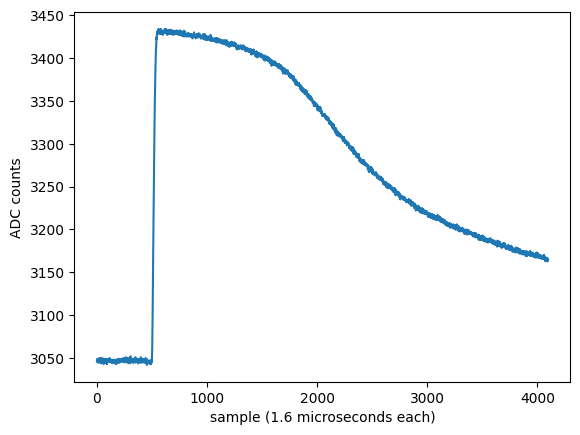

In [7]:
import matplotlib.pyplot as plt

plt.plot(pulses[1095])
plt.xlabel("sample (1.6 microseconds each)")
plt.ylabel("ADC counts")
plt.show()

In [6]:
from dataclasses import replace
from pulse_config import DEFAULT_CONFIG
import pulse_quantities as pq
import pulse_cuts as pc
import numpy as np

c500 = replace(DEFAULT_CONFIG, pretrigger_samples=500)
quiet = pc.excursion_band(pulses, c500) & (np.log10(pq.bstd(pulses)) < 0.5)
print(quiet.sum())

179


I imported a data dump from NSDF and ran an environment check to see if my program met the project's requirements list. Then, the data was read into my computer's memory and named "cdms". I took every trace from detector 0, channel 0 and put them into a table. The size of the table was printed in rows, columns as 1517, 4096. I created a plot of this data with ADC counts and samples (1.6 μs) from 0 to 4000 samples. This results in a clear pulse at sample 1095.
I  created a copy of the data dump and applied the project's default settings for the baseline window. Functions were imported to determine whether or not traces should be kept based on baseline wobble. I made a test for these traces to see if they met the criteria of Note 2 and had a small baseline wobble. The total number of traces that passed the test was printed as 179. 